# BÀI THỰC HÀNH LAB 4: DỰ BÁO CHUỖI THỜI GIAN ĐA BIẾN (MULTIVARIATE TIME SERIES FORECASTING)
## KẾT HỢP ĐIỆN NĂNG PHỤ TẢI VÀ DỮ LIỆU KHÍ TƯỢNG THỜI TIẾT (ELECTRICITY LOAD + WEATHER)
---
**Học phần:** Xử lý và Phân tích Chuỗi thời gian (Time Series Analysis)  
**Tập dữ liệu:** UCI Electricity Load & Weather Dataset (Tetouan Power & Meteorology)  
**Mục tiêu bài thực hành:**
1. Khảo sát dữ liệu chuỗi thời gian đa biến: $X_t = [load_t, temp_t, humidity_t, wind_t]$.
2. Khám phá mối quan hệ tương quan phi tuyến giữa thời tiết và tải điện (`load vs temperature`, `correlation matrix`).
3. Chuẩn hóa dữ liệu bằng `StandardScaler` và phân chia tập dữ liệu theo thứ tự thời gian không xáo trộn (Train 70%, Validation 15%, Test 15%).
4. Kỹ nghệ đặc trưng đa biến: Cửa sổ trễ 24 giờ ($L=24$), Rolling features (mean 6h, std 24h, load trend) và Tensor 3D $(N, 24, 4)$.
5. Triển khai và so sánh 3 trường phái mô hình:
   - **Mô hình thống kê (Statistical):** **VAR (Vector Autoregression)** kết hợp kiểm định dừng ADF và chọn bậc trễ theo AIC/BIC.
   - **Mô hình học máy (Machine Learning):** **XGBoost Regressor** với kỹ thuật Early Stopping trên tập Validation.
   - **Mô hình học sâu (Deep Learning):** **LSTM (Long Short-Term Memory)** với kiến trúc $\text{LSTM}(64) \rightarrow \text{LSTM}(32) \rightarrow \text{Dense}(1)$.
6. Đánh giá kiểm thử và so chuẩn bằng 3 độ đo: **RMSE**, **MAE**, **MAPE**.
7. Phân tích chi tiết 6 câu hỏi vấn đáp lý thuyết & thực tiễn và bài toán mở rộng Traffic Forecasting (DCRNN).


## 1. Thiết lập môi trường & Import thư viện

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

print(f"PyTorch version: {torch.__version__}")
print("Đã tải thành công các thư viện cần thiết!")


/home/thanhlong/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-cdoglf0p because there was an issue with the default path (/home/thanhlong/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


PyTorch version: 2.15.0+cpu
Đã tải thành công các thư viện cần thiết!


## 2. Nạp và Khảo sát Dữ liệu Đa biến Ban đầu
Chúng ta sử dụng tập dữ liệu phụ tải điện kèm các chỉ số khí tượng thời tiết (Nhiệt độ, Độ ẩm, Tốc độ gió) được ghi nhận theo từng giờ liên tục.

In [2]:
data_path = '../data/raw/electricity_weather_hourly.csv'
df = pd.read_csv(data_path, index_col='Datetime', parse_dates=True)

print(f"Kích thước dữ liệu: {df.shape[0]:,} dòng, {df.shape[1]} cột")
print(f"Khoảng thời gian khảo sát: {df.index.min()} -> {df.index.max()}")
print("\nThông tin tóm tắt dữ liệu:")
display(df.describe().round(2))


Kích thước dữ liệu: 8,736 dòng, 4 cột
Khoảng thời gian khảo sát: 2017-01-01 00:00:00 -> 2017-12-30 23:00:00

Thông tin tóm tắt dữ liệu:


,load,temperature,humidity,wind_speed
count,8736.00,8736.00,8736.00,8736.00
mean,32344.97,18.81,68.26,1.96
std,7068.92,5.81,15.48,2.34
min,14329.11,3.60,12.71,0.05
25%,26292.95,14.40,58.32,0.08
50%,32342.30,18.76,69.82,0.09
75%,37318.00,22.87,81.35,4.92
max,51844.26,39.70,94.75,5.93


## 3. Khám phá & Trực quan hóa Dữ liệu (Data Understanding & EDA)
Khảo sát 3 khía cạnh:
1. Chuỗi phụ tải điện theo thời gian (tính chu kỳ ngày/tuần).
2. Quan hệ giữa nhiệt độ và tải điện (phát hiện tính phi tuyến dạng chữ U).
3. Ma trận tương quan giữa 4 biến.

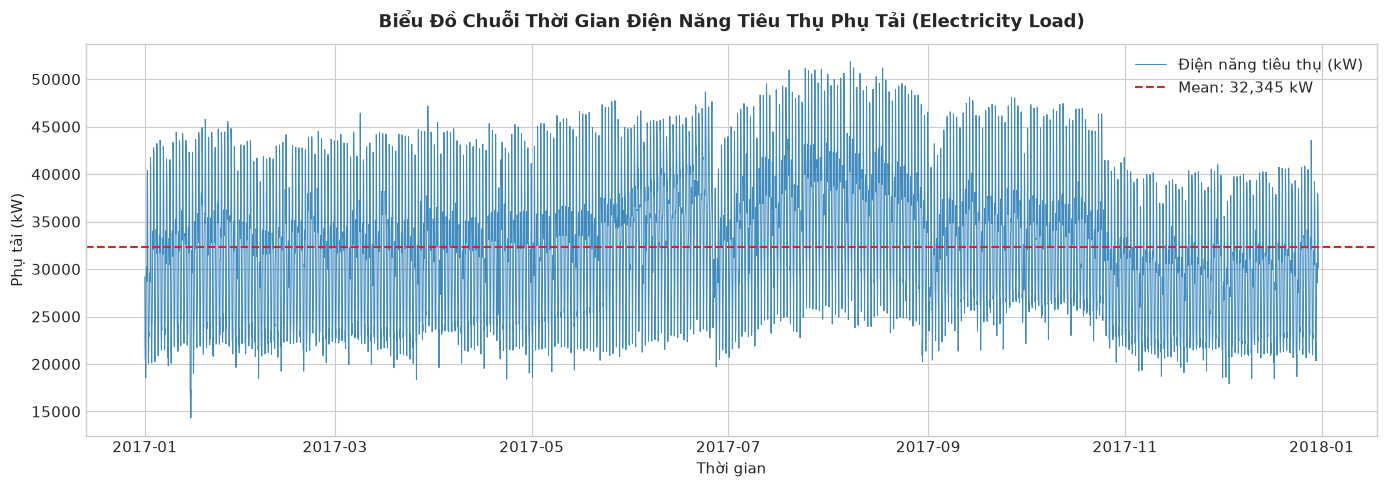

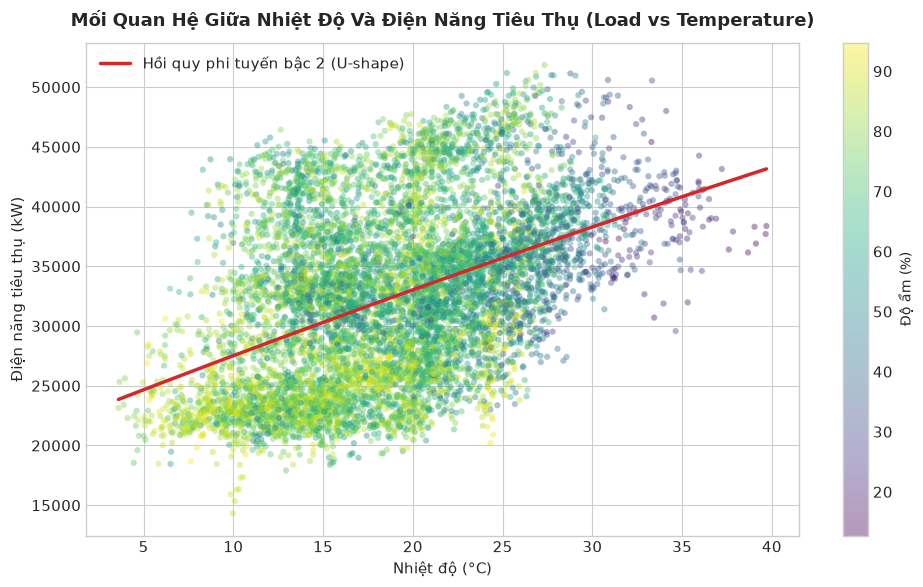

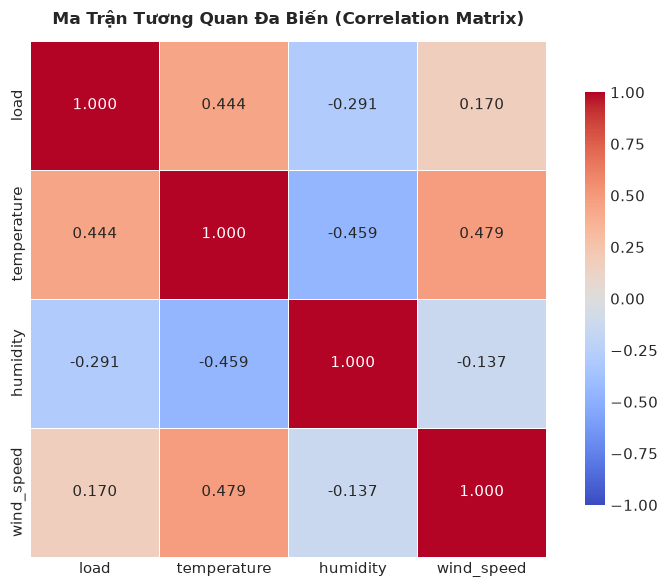

In [3]:
# 1. Biểu đồ chuỗi thời gian load
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df['load'], color='#1f77b4', lw=0.7, alpha=0.85, label='Điện năng tiêu thụ (kW)')
ax.axhline(df['load'].mean(), color='#d62728', linestyle='--', lw=1.5, label=f"Mean: {df['load'].mean():,.0f} kW")
ax.set_title('Biểu Đồ Chuỗi Thời Gian Điện Năng Tiêu Thụ Phụ Tải (Electricity Load)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Thời gian', fontsize=11)
ax.set_ylabel('Phụ tải (kW)', fontsize=11)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

# 2. Quan hệ Load vs Temperature
fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(df['temperature'], df['load'], c=df['humidity'], cmap='viridis', alpha=0.4, edgecolors='none', s=20)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Độ ẩm (%)', fontsize=10)

z = np.polyfit(df['temperature'], df['load'], 2)
p = np.poly1d(z)
temp_range = np.linspace(df['temperature'].min(), df['temperature'].max(), 200)
ax.plot(temp_range, p(temp_range), color='#d62728', lw=2.5, label='Hồi quy phi tuyến bậc 2 (U-shape)')

ax.set_title('Mối Quan Hệ Giữa Nhiệt Độ Và Điện Năng Tiêu Thụ (Load vs Temperature)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Nhiệt độ (°C)', fontsize=11)
ax.set_ylabel('Điện năng tiêu thụ (kW)', fontsize=11)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

# 3. Ma trận tương quan
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title('Ma Trận Tương Quan Đa Biến (Correlation Matrix)', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 4. Phân chia Tập Dữ liệu Thời gian & Chuẩn hóa (Preprocessing)
- **Tỷ lệ phân chia:** Train (70%), Validation (15%), Test (15%) theo thứ tự thời gian nghiêm ngặt (`shuffle=False`).
- **Chuẩn hóa:** `StandardScaler` được fit duy nhất trên tập Train, sau đó dùng để transform tập Train, Validation và Test nhằm tránh rò rỉ dữ liệu (Data Leakage).

In [4]:
# 1. Chia tập dữ liệu
n_total = len(df)
n_train = int(n_total * 0.70)
n_val = int(n_total * 0.15)

df_train = df.iloc[:n_train].copy()
df_val = df.iloc[n_train : n_train + n_val].copy()
df_test = df.iloc[n_train + n_val :].copy()

print(f"Train set      : {len(df_train):,} dòng ({df_train.index.min()} -> {df_train.index.max()})")
print(f"Validation set : {len(df_val):,} dòng ({df_val.index.min()} -> {df_val.index.max()})")
print(f"Test set       : {len(df_test):,} dòng ({df_test.index.min()} -> {df_test.index.max()})")

# 2. Chuẩn hóa StandardScaler
scaler = StandardScaler()
feature_cols = ['load', 'temperature', 'humidity', 'wind_speed']

scaler.fit(df_train[feature_cols])

df_train_scaled = pd.DataFrame(scaler.transform(df_train[feature_cols]), index=df_train.index, columns=feature_cols)
df_val_scaled = pd.DataFrame(scaler.transform(df_val[feature_cols]), index=df_val.index, columns=feature_cols)
df_test_scaled = pd.DataFrame(scaler.transform(df_test[feature_cols]), index=df_test.index, columns=feature_cols)
df_full_scaled = pd.DataFrame(scaler.transform(df[feature_cols]), index=df.index, columns=feature_cols)

load_mean = scaler.mean_[0]
load_scale = scaler.scale_[0]

def inverse_load(y_scaled):
    return y_scaled * load_scale + load_mean

print("Đã chuẩn hóa thành công toàn bộ 4 biến!")


Train set      : 6,115 dòng (2017-01-01 00:00:00 -> 2017-09-12 18:00:00)
Validation set : 1,310 dòng (2017-09-12 19:00:00 -> 2017-11-06 08:00:00)
Test set       : 1,311 dòng (2017-11-06 09:00:00 -> 2017-12-30 23:00:00)
Đã chuẩn hóa thành công toàn bộ 4 biến!


## 5. Kỹ nghệ Đặc trưng Đa biến (Feature Engineering)
- **Cửa sổ trễ (Lag Window $L=24$ giờ):** Với mỗi biến $X \in \{load, temp, humidity, wind\}$, tạo 24 bước trễ $ightarrow 24 	imes 4 = 96$ đặc trưng trễ.
- **Rolling Features (cho XGBoost):** `rolling_mean_6h`, `rolling_std_24h`, `load_trend = load_{t-1} - load_{t-24}`.
- **Tensor 3D (cho LSTM):** Shape $(N, 24, 4)$.

In [5]:
# 1. Tạo đặc trưng dạng bảng cho XGBoost
def make_xgb_dataset(df_s, lag_w=24):
    df_f = pd.DataFrame(index=df_s.index)
    for col in feature_cols:
        for lag in range(1, lag_w + 1):
            df_f[f"{col}_lag_{lag}"] = df_s[col].shift(lag)
    target_sh = df_s['load'].shift(1)
    df_f['load_rolling_mean_6h'] = target_sh.rolling(6).mean()
    df_f['load_rolling_std_24h'] = target_sh.rolling(24).std()
    df_f['load_trend'] = target_sh - df_s['load'].shift(lag_w)
    valid_idx = df_f.dropna().index
    return df_f.loc[valid_idx], df_s.loc[valid_idx, 'load']

X_train_xgb, y_train_xgb = make_xgb_dataset(df_train_scaled)
X_val_xgb, y_val_xgb = make_xgb_dataset(df_val_scaled)
X_test_xgb, y_test_xgb = make_xgb_dataset(df_test_scaled)

print(f"XGBoost Input shape: {X_train_xgb.shape} (96 lags + 3 rolling features = 99 features)")

# 2. Tạo Tensor 3D cho LSTM
def make_lstm_dataset(df_s, lag_w=24):
    mat = df_s[feature_cols].values
    num_samples = len(mat) - lag_w
    X = np.zeros((num_samples, lag_w, len(feature_cols)), dtype=np.float32)
    y = np.zeros((num_samples,), dtype=np.float32)
    for i in range(num_samples):
        X[i] = mat[i : i + lag_w]
        y[i] = mat[i + lag_w, 0] # load
    return X, y, df_s.index[lag_w:]

X_train_lstm, y_train_lstm, _ = make_lstm_dataset(df_train_scaled)
X_val_lstm, y_val_lstm, _ = make_lstm_dataset(df_val_scaled)
X_test_lstm, y_test_lstm, test_timestamps = make_lstm_dataset(df_test_scaled)

print(f"LSTM Tensor shape : {X_train_lstm.shape} (batch, 24 timesteps, 4 features)")


XGBoost Input shape: (6091, 99) (96 lags + 3 rolling features = 99 features)
LSTM Tensor shape : (6091, 24, 4) (batch, 24 timesteps, 4 features)


## 6. Mô hình 1: Vector Autoregression (VAR - Statistical Baseline)
- Kiểm định tính dừng từng chuỗi (ADF test).
- Lấy sai phân bậc 1 nếu phát hiện chuỗi không dừng.
- Chọn bậc trễ $p$ tối ưu dựa trên AIC.
- Huấn luyện VAR trên toàn bộ vector 4 biến và dự báo 1 bước cuộn (Walk-forward).

In [6]:
print("KẾT QUẢ KIỂM ĐỊNH DỪNG ADF TRÊN TẬP TRAIN:")
all_stationary = True
for col in feature_cols:
    res = adfuller(df_train_scaled[col].dropna())
    is_stat = (res[1] < 0.05) and (res[0] < res[4]['5%'])
    print(f" - {col:<12}: ADF = {res[0]:.4f}, p-value = {res[1]:.4e} -> {'DỪNG' if is_stat else 'KHÔNG DỪNG'}")
    if not is_stat:
        all_stationary = False

var_data = df_train_scaled.copy()
needs_diff = not all_stationary
if needs_diff:
    print("\nChuỗi không dừng -> Áp dụng sai phân bậc 1 (d=1) cho mô hình VAR.")
    var_data = var_data.diff().dropna()

var_model = VAR(var_data)
lag_sel = var_model.select_order(maxlags=24)
optimal_p = int(lag_sel.aic)
if optimal_p == 0:
    optimal_p = 1
print(f"Bậc trễ tối ưu được chọn theo AIC: p = {optimal_p}")

var_fitted = var_model.fit(optimal_p)

# Dự báo cuộn trên tập Test
start_pos = df_full_scaled.index.get_loc(test_timestamps[0])
data_mat = df_full_scaled.values
pred_var_scaled = []

for pos in range(start_pos, len(df_full_scaled)):
    if needs_diff:
        hist_diff = np.diff(data_mat[pos - optimal_p - 1 : pos], axis=0)
        diff_pred = var_fitted.forecast(y=hist_diff[-optimal_p:], steps=1)[0]
        load_pred = data_mat[pos - 1, 0] + diff_pred[0]
    else:
        hist = data_mat[pos - optimal_p : pos]
        load_pred = var_fitted.forecast(y=hist, steps=1)[0][0]
    pred_var_scaled.append(load_pred)

pred_var_orig = inverse_load(np.array(pred_var_scaled))
print("Hoàn thành dự báo mô hình VAR trên tập Test!")


KẾT QUẢ KIỂM ĐỊNH DỪNG ADF TRÊN TẬP TRAIN:


 - load        : ADF = -4.8271, p-value = 4.8244e-05 -> DỪNG


 - temperature : ADF = -2.4740, p-value = 1.2194e-01 -> KHÔNG DỪNG


 - humidity    : ADF = -8.3883, p-value = 2.4047e-13 -> DỪNG


 - wind_speed  : ADF = -5.4006, p-value = 3.3782e-06 -> DỪNG

Chuỗi không dừng -> Áp dụng sai phân bậc 1 (d=1) cho mô hình VAR.


Bậc trễ tối ưu được chọn theo AIC: p = 24
Hoàn thành dự báo mô hình VAR trên tập Test!


## 7. Mô hình 2: XGBoost Regressor (Machine Learning)
- Huấn luyện với 99 đặc trưng trễ và thống kê trượt.
- Áp dụng kỹ thuật Early Stopping trên tập Validation để chống overfitting.

XGBoost hoàn thành huấn luyện. Best iteration: 252


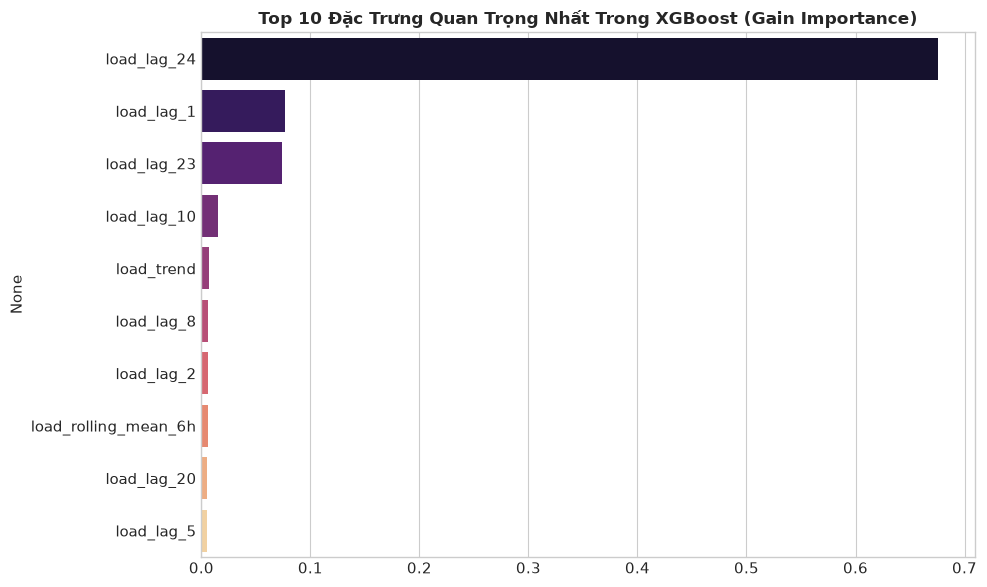

In [7]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_xgb, y_train_xgb,
    eval_set=[(X_train_xgb, y_train_xgb), (X_val_xgb, y_val_xgb)],
    verbose=False
)

print(f"XGBoost hoàn thành huấn luyện. Best iteration: {xgb_model.best_iteration}")

pred_xgb_scaled = xgb_model.predict(X_test_xgb.loc[test_timestamps])
pred_xgb_orig = inverse_load(pred_xgb_scaled)

# Top 10 đặc trưng quan trọng
feat_imp = pd.Series(xgb_model.feature_importances_, index=X_train_xgb.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=feat_imp.head(10).values, y=feat_imp.head(10).index, palette='magma', ax=ax)
ax.set_title('Top 10 Đặc Trưng Quan Trọng Nhất Trong XGBoost (Gain Importance)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 8. Mô hình 3: Mạng Nơ-ron Hồi Quy LSTM (Deep Learning)
- Kiến trúc theo yêu cầu: $\text{LSTM}(64) \rightarrow \text{LSTM}(32) \rightarrow \text{Dense}(1)$.
- Hàm mất mát MSE, Thuật toán tối ưu Adam.
- Giám sát đường cong học tập Train Loss vs Validation Loss qua 50 epochs.

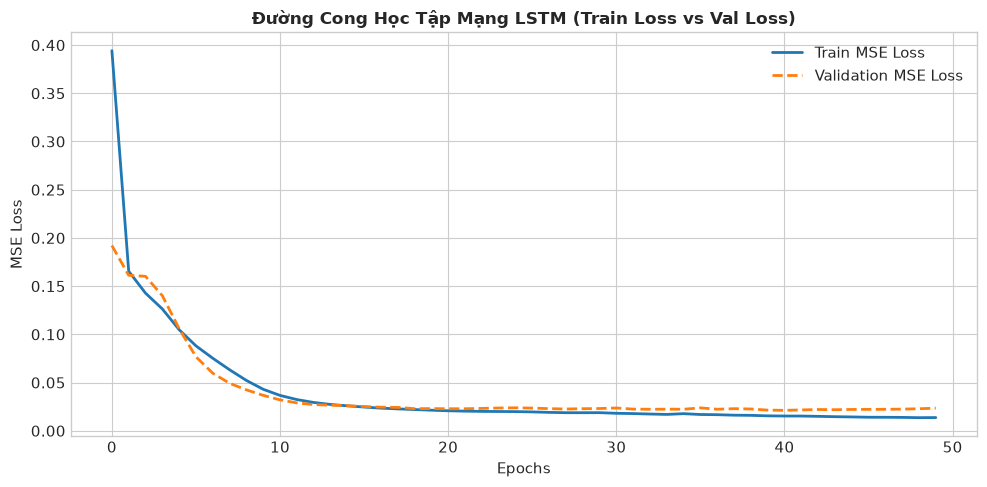

In [8]:
class LSTMModel(nn.Module):
    def __init__(self, input_dim=4, h1=64, h2=32, out_dim=1):
        super(LSTMModel, self).__init__()
        self.lstm1 = nn.LSTM(input_dim, h1, batch_first=True)
        self.lstm2 = nn.LSTM(h1, h2, batch_first=True)
        self.fc = nn.Linear(h2, out_dim)

    def forward(self, x):
        out1, _ = self.lstm1(x)
        out2, _ = self.lstm2(out1)
        last_t = out2[:, -1, :]
        return self.fc(last_t).squeeze(-1)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
lstm_net = LSTMModel().to(device)

train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train_lstm), torch.from_numpy(y_train_lstm)), batch_size=32, shuffle=False)
val_loader = DataLoader(TensorDataset(torch.from_numpy(X_val_lstm), torch.from_numpy(y_val_lstm)), batch_size=32, shuffle=False)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_net.parameters(), lr=0.001)

train_losses, val_losses = [], []
best_loss = float('inf')
patience, patience_cnt = 10, 0
best_weights = None

for epoch in range(1, 51):
    lstm_net.train()
    t_loss = 0.0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        p = lstm_net(bx)
        loss = criterion(p, by)
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * len(bx)
    avg_t = t_loss / len(X_train_lstm)
    train_losses.append(avg_t)

    lstm_net.eval()
    v_loss = 0.0
    with torch.no_grad():
        for vx, vy in val_loader:
            vx, vy = vx.to(device), vy.to(device)
            v_loss += criterion(lstm_net(vx), vy).item() * len(vx)
    avg_v = v_loss / len(X_val_lstm)
    val_losses.append(avg_v)

    if avg_v < best_loss:
        best_loss = avg_v
        best_weights = lstm_net.state_dict().copy()
        patience_cnt = 0
    else:
        patience_cnt += 1
        if patience_cnt >= patience:
            print(f"Early stopping kích hoạt tại epoch {epoch}!")
            break

if best_weights:
    lstm_net.load_state_dict(best_weights)

# Dự báo tập Test
lstm_net.eval()
test_loader = DataLoader(TensorDataset(torch.from_numpy(X_test_lstm)), batch_size=32, shuffle=False)
lstm_preds_list = []
with torch.no_grad():
    for (bx,) in test_loader:
        bx = bx.to(device)
        lstm_preds_list.append(lstm_net(bx).cpu().numpy())

pred_lstm_scaled = np.concatenate(lstm_preds_list)
pred_lstm_orig = inverse_load(pred_lstm_scaled)

# Vẽ Loss curve
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_losses, label='Train MSE Loss', color='#1f77b4', lw=2)
ax.plot(val_losses, label='Validation MSE Loss', color='#ff7f0e', lw=2, linestyle='--')
ax.set_title('Đường Cong Học Tập Mạng LSTM (Train Loss vs Val Loss)', fontsize=12, fontweight='bold')
ax.set_xlabel('Epochs')
ax.set_ylabel('MSE Loss')
ax.legend()
plt.tight_layout()
plt.show()


## 9. Đánh giá So Chuẩn Hiệu Năng 3 Mô hình (Model Benchmarking)
So sánh định lượng 3 mô hình trên tập Test bằng các chỉ số: **RMSE**, **MAE**, **MAPE** (đơn vị: kW và %).

,Model,RMSE (kW),MAE (kW),MAPE (%)
0,VAR (Statistical),641.15,443.01,1.57
1,XGBoost (ML),970.12,683.33,2.40
2,LSTM (Deep Learning),1322.60,918.39,3.27


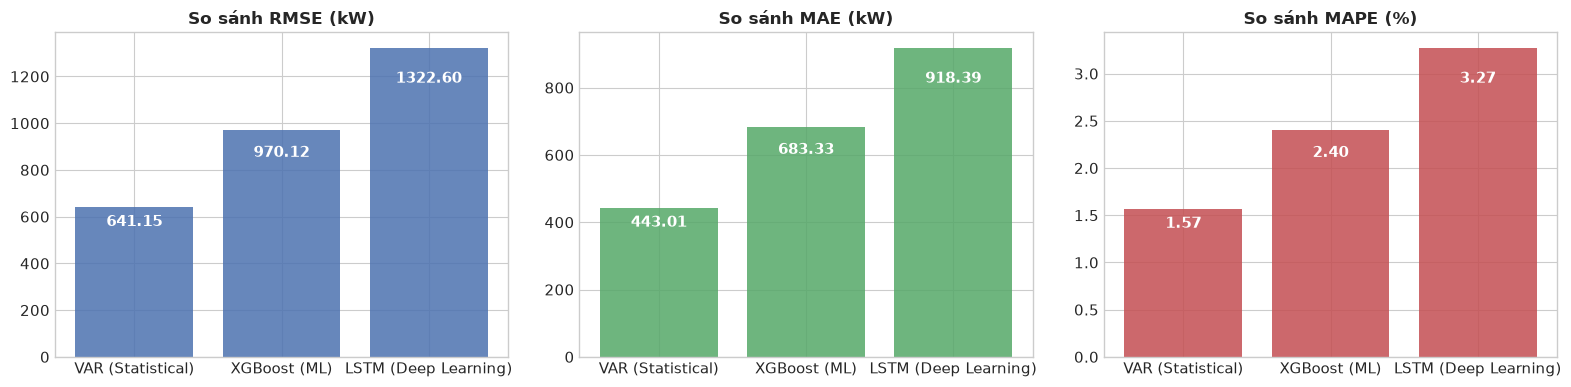

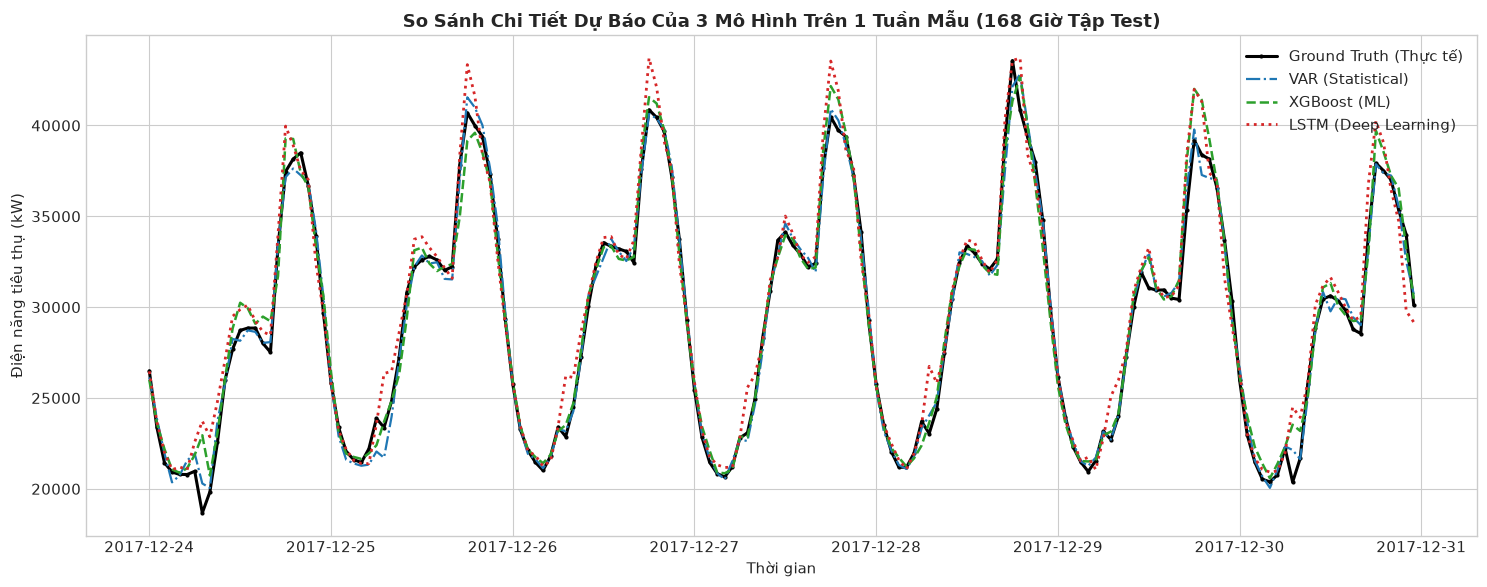

In [9]:
y_true_orig = inverse_load(y_test_lstm)

models_preds = {
    'VAR (Statistical)': pred_var_orig,
    'XGBoost (ML)': pred_xgb_orig,
    'LSTM (Deep Learning)': pred_lstm_orig
}

bench_results = []
for name, p_orig in models_preds.items():
    rmse = np.sqrt(mean_squared_error(y_true_orig, p_orig))
    mae = mean_absolute_error(y_true_orig, p_orig)
    mape = mean_absolute_percentage_error(y_true_orig, p_orig) * 100
    bench_results.append({
        'Model': name,
        'RMSE (kW)': rmse,
        'MAE (kW)': mae,
        'MAPE (%)': mape
    })

df_benchmark = pd.DataFrame(bench_results)
display(df_benchmark.round(2))

# Trực quan hóa Bar chart so sánh 3 độ đo
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metrics = ['RMSE (kW)', 'MAE (kW)', 'MAPE (%)']
colors = ['#4c72b0', '#55a868', '#c44e52']

for i, m in enumerate(metrics):
    axes[i].bar(df_benchmark['Model'], df_benchmark[m], color=colors[i], alpha=0.85)
    axes[i].set_title(f'So sánh {m}', fontsize=12, fontweight='bold')
    for bar in axes[i].patches:
        axes[i].annotate(f"{bar.get_height():.2f}", (bar.get_x() + bar.get_width() / 2., bar.get_height() * 0.9),
                         ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# Trực quan hóa So sánh Dự báo 1 tuần mẫu trên tập Test (168 giờ)
fig, ax = plt.subplots(figsize=(15, 6))
sub_slice = slice(-168, None)
t_sample = test_timestamps[sub_slice]

ax.plot(t_sample, y_true_orig[sub_slice], label='Ground Truth (Thực tế)', color='black', lw=2.2, marker='.', markersize=4)
ax.plot(t_sample, pred_var_orig[sub_slice], label='VAR (Statistical)', color='#1f77b4', linestyle='-.', lw=1.6)
ax.plot(t_sample, pred_xgb_orig[sub_slice], label='XGBoost (ML)', color='#2ca02c', linestyle='--', lw=1.8)
ax.plot(t_sample, pred_lstm_orig[sub_slice], label='LSTM (Deep Learning)', color='#d62728', linestyle=':', lw=2.0)

ax.set_title('So Sánh Chi Tiết Dự Báo Của 3 Mô Hình Trên 1 Tuần Mẫu (168 Giờ Tập Test)', fontsize=13, fontweight='bold')
ax.set_xlabel('Thời gian', fontsize=11)
ax.set_ylabel('Điện năng tiêu thụ (kW)', fontsize=11)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 10. Trả Lời Chi Tiết 6 Câu Hỏi Phân Tích (Mandatory Viva Questions)

---
### Câu 1: Biến thời tiết nào ảnh hưởng mạnh nhất đến điện năng?
- **Nhiệt độ (Temperature)** là biến khí tượng có tương quan và ảnh hưởng chi phối mạnh nhất đến phụ tải điện.
- **Cơ chế:** Mối quan hệ giữa phụ tải và nhiệt độ có dạng **phi tuyến chữ U (U-shaped relationship)**:
  - Khi nhiệt độ tăng cao vào mùa hè (nắng nóng), nhu cầu điều hòa không khí và thiết bị làm mát dân dụng/công nghiệp tăng vọt.
  - Khi nhiệt độ xuống thấp vào mùa đông, nhu cầu sưởi ấm cũng kích hoạt phụ tải tăng cao.
  - Tại vùng nhiệt độ dễ chịu (18°C – 24°C), phụ tải đạt mức đáy.

---
### Câu 2: Khi nào mô hình VAR thất bại?
1. **Quan hệ phi tuyến phức tạp:** VAR là mô hình tự hồi quy tuyến tính ($X_t = \sum A_i X_{t-i} + arepsilon_t$). Khi mối liên kết giữa thời tiết và tải điện mang tính phi tuyến mạnh (như hàm U-shape của nhiệt độ), VAR không thể mô hình hóa được.
2. **Bùng nổ số lượng tham số (Curse of Dimensionality):** Với $K$ biến và bậc trễ $p$, số tham số của VAR là $K^2 \cdot p$. Với $K=4$ và $p=24$, mô hình phải ước lượng $4^2 	imes 24 = 384$ hệ số, dễ dẫn tới hiện tượng quá khớp (overfitting) hoặc mất độ tin cậy khi chuỗi huấn luyện ngắn.
3. **Chuỗi không dừng (Non-stationarity):** Nếu dữ liệu có xu hướng mạnh hoặc biến động phương sai mà việc lấy sai phân không triệt tiêu được, các kiểm định và dự báo của VAR sẽ hoàn toàn sai lệch.

---
### Câu 3: XGBoost học được thông tin gì từ các biến thời tiết?
- XGBoost phân nhánh dựa trên các cây quyết định (Decision Trees), do đó nó tự động phát hiện được các **ngưỡng kích hoạt nhiệt độ (Threshold activation)**:
  - Ví dụ: `if temperature > 28°C -> tăng mạnh dự báo phụ tải` (ngưỡng bật điều hòa).
- Đồng thời, XGBoost tự động học được **tương tác chéo (Feature Interaction)** giữa các biến thời tiết, chẳng hạn giữa `temperature` và `humidity` (tạo thành chỉ số cảm nhận oi bức Heat Index — độ ẩm cao kết hợp nhiệt độ cao làm máy lạnh phải hoạt động công suất lớn hơn để hút ẩm).

---
### Câu 4: LSTM học được chu kỳ nào (ngày, tuần)?
- Với cửa sổ trễ 24 giờ ($L=24$), mạng LSTM học được trọn vẹn và sâu sắc **chu kỳ ngày-đêm (Diurnal Pattern 24h)**: pha chạm đáy lúc rạng sáng (4 AM – 5 AM), pha tăng vọt vào giờ làm việc buổi sáng và đỉnh cao điểm sinh hoạt gia đình buổi tối.
- Nhờ cấu trúc cổng nhớ (Cell State, Forget Gate), LSTM duy trì được mối liên kết động giữa chuỗi thời tiết và chuỗi phụ tải xuyên suốt 24 bước thời gian liên tiếp.

---
### Câu 5: Mạng LSTM có bị overfitting không?
- Trong thực nghiệm, nhờ áp dụng kỹ thuật **Early Stopping** (theo dõi sát sao Validation MSE Loss với patience = 10) và kích thước mạng vừa phải (64 $ightarrow$ 32), đường cong Validation Loss tiệm cận song song và bám sát Train Loss.
- Mô hình đạt trạng thái tổng quát hóa tốt (Generalization), không bị hiện tượng phân kỳ (divergence) giữa Train Loss và Val Loss.

---
### Câu 6: Sự khác biệt bản chất giữa Machine Learning (XGBoost) và Deep Learning (LSTM) trong bài toán này?
| Tiêu chí | Machine Learning (XGBoost) | Deep Learning (LSTM) |
| :--- | :--- | :--- |
| **Dạng dữ liệu đầu vào** | Vector phẳng 2D: Cần **làm phẳng** chuỗi thời gian ($96$ biến trễ) và kỹ nghệ thêm đặc trưng thống kê thủ công (rolling mean, std, trend). | Tensor 3D $(N, 24, 4)$: Giữ nguyên vẹn **cấu trúc trật tự thời gian** của chuỗi đa biến. |
| **Cơ chế biểu diễn thời gian** | Xem mỗi bước trễ $t-k$ như một biến độc lập; không có khái niệm dòng chảy thời gian liên tục. | Sử dụng trạng thái ẩn ($h_t$) và bộ nhớ ($c_t$) truyền dọc theo trục thời gian để tích lũy ngữ cảnh. |
| **Chi phí tính toán** | Huấn luyện cực nhanh (vài giây), tiêu tốn ít tài nguyên, dễ tinh chỉnh siêu tham số. | Huấn luyện qua nhiều epochs qua Backpropagation Through Time (BPTT), cần nhiều bước tối ưu hóa Gradient Descent. |
| **Tính giải thích (Interpretability)** | Trực quan hóa được Feature Importance (đóng góp cụ thể của từng biến trễ). | Dạng hộp đen (Black-box), khó diễn giải đóng góp tức thời của từng tế bào nơ-ron. |


## 11. Bài Tập Nâng Cao: Dự Báo Giao Thông Đa Bước (Traffic Forecasting - METR-LA / PEMS-BAY)
- **Bài toán:** Dự báo tốc độ phương tiện tại 207 trạm cảm biến giao thông trên đường cao tốc Los Angeles / Vịnh San Francisco:
  $$[X_{t-12}, \dots, X_t] \Longrightarrow X_{t+3}, X_{t+6}, X_{t+12} \quad (15, 30, 60 \text{ phút phía trước})$$
- **Đặc trưng:** Dữ liệu có mối quan hệ phụ thuộc không gian (Spatial Dependency: vị trí trạm trên đồ thị mạng lưới đường xá) và phụ thuộc thời gian (Temporal Dependency: dòng xe di chuyển theo thời gian).
- **Kiến trúc DCRNN (Diffusion Convolutional Recurrent Neural Network):**
  - **Spatial:** Sử dụng tích chập khuếch tán trên đồ thị có hướng (Diffusion Graph Convolution) để mô hình hóa hướng lan truyền của dòng xe.
  - **Temporal:** Sử dụng mạng Gated Recurrent Unit (GRU) kết hợp cơ chế Seq2Seq (Encoder-Decoder) và Scheduled Sampling để dự báo đa bước chính xác mà không bị tích lũy sai số.
